# 🎙️ Emotion Recognition from Speech — CodeAlpha ML Internship (Task 2)

**Objective:** recognise emotions (neutral, calm, happy, sad, angry, fear, disgust, surprise) from speech audio.

**Data:** [RAVDESS](https://www.kaggle.com/datasets/uwrfkaggler/ravdess-emotional-speech-audio) (required) · [TESS](https://www.kaggle.com/datasets/ejlok1/toronto-emotional-speech-set-tess) (optional)

**Approach:** MFCC feature extraction → CNN + BiLSTM deep learning model


## 1. Setup — imports & settings
`SPLIT = "speaker"` tests on actors the model has never heard (realistic); `"random"` gives the higher speaker-dependent score.

In [1]:
import glob, json, os, warnings
import librosa
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from joblib import Parallel, delayed
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from tensorflow import keras
from tensorflow.keras import layers

warnings.filterwarnings("ignore")
USE_TESS = True            # also use TESS if it is attached
SPLIT = "speaker"          # "speaker" = unseen actors in test (honest) | "random" = speaker-dependent
AUGMENT = True
EPOCHS = 100
SEED = 42
SR, DURATION, N_MFCC, HOP = 22050, 3.0, 40, 512
N_SAMPLES = int(SR * DURATION)
INPUT = "/kaggle/input" if os.path.exists("/kaggle/input") else "."
OUT = "/kaggle/working/outputs" if os.path.exists("/kaggle/working") else "outputs"
os.makedirs(OUT, exist_ok=True)
tf.random.set_seed(SEED); np.random.seed(SEED)
print("GPU:", tf.config.list_physical_devices("GPU"))

2026-11-25 02:50:09.649844: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1795575009.891577      57 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1795575009.970782      57 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1795575010.601119      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1795575010.601154      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1795575010.601156      57 computation_placer.cc:177] computation placer alr

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 2. Find audio files & parse emotion labels
RAVDESS: `03-01-05-01-02-01-12.wav` → 3rd field = emotion (05 = angry), last field = actor. TESS: `OAF_back_angry.wav` → last word = emotion. Duplicate copies inside the Kaggle datasets are skipped.

In [2]:
RAVDESS = {"01": "neutral", "02": "calm", "03": "happy", "04": "sad",
           "05": "angry", "06": "fear", "07": "disgust", "08": "surprise"}
TESS = {"angry": "angry", "disgust": "disgust", "fear": "fear", "happy": "happy",
        "neutral": "neutral", "ps": "surprise", "sad": "sad"}

items, seen = [], set()
for p in sorted(glob.glob(f"{INPUT}/**/*.wav", recursive=True)):
    base = os.path.basename(p)
    if base.lower() in seen:                     # Kaggle copies contain the same files twice
        continue
    parts = base[:-4].split("-")
    if len(parts) == 7 and parts[0] == "03" and parts[1] == "01" and parts[2] in RAVDESS:
        items.append({"path": p, "label": RAVDESS[parts[2]], "speaker": int(parts[6]), "corpus": "ravdess"})
        seen.add(base.lower())
    elif USE_TESS:
        emo = base[:-4].split("_")[-1].lower()
        if emo not in TESS:                      # fallback: label from folder name (e.g. OAF_Pleasant_surprise)
            folder = os.path.basename(os.path.dirname(p)).lower()
            emo = "ps" if "surprise" in folder else folder.split("_")[-1]
        if emo in TESS and base[:3].upper() in ("OAF", "YAF"):
            items.append({"path": p, "label": TESS[emo], "speaker": base.split("_")[0].upper(), "corpus": "tess"})
            seen.add(base.lower())
assert items, "No audio found - attach the RAVDESS dataset"
classes = sorted({i["label"] for i in items})
print(f"{len(items)} clips  |  RAVDESS {sum(i['corpus'] == 'ravdess' for i in items)}  "
      f"TESS {sum(i['corpus'] == 'tess' for i in items)}  |  classes: {classes}")

4239 clips  |  RAVDESS 1440  TESS 2799  |  classes: ['angry', 'calm', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


## 3. Train / validation / test split
RAVDESS actors 1–18 train, 19–20 validation, **21–24 test (unseen voices)**. TESS has only 2 speakers, so it is split randomly.

In [3]:
def strat_split(lst, size):
    return train_test_split(lst, test_size=size, stratify=[i["label"] for i in lst], random_state=SEED)


if SPLIT == "random":
    tr, te = strat_split(items, 0.15)
    tr, va = strat_split(tr, 0.15 / 0.85)
else:                                            # RAVDESS actors 21-24 test, 19-20 validation
    rav = [i for i in items if i["corpus"] == "ravdess"]
    tess = [i for i in items if i["corpus"] == "tess"]
    tr = [i for i in rav if i["speaker"] <= 18]
    va = [i for i in rav if i["speaker"] in (19, 20)]
    te = [i for i in rav if i["speaker"] >= 21]
    if tess:                                     # TESS has only 2 speakers -> stratified random split
        t_tr, t_te = strat_split(tess, 0.15)
        t_tr, t_va = strat_split(t_tr, 0.15 / 0.85)
        tr, va, te = tr + t_tr, va + t_va, te + t_te
print(f"split={SPLIT}: train {len(tr)} | val {len(va)} | test {len(te)}")

split=speaker: train 3039 | val 540 | test 660


## 4. Audio preprocessing, augmentation & MFCC features
- trim silence, pad/crop to 3 s at 22.05 kHz
- **augmentation (training only):** noise, pitch shift, time stretch
- **features:** 40 MFCCs + Δ + ΔΔ + RMS energy + zero-crossing rate → 130 frames × 122 features

In [4]:
def load_audio(path):
    y, _ = librosa.load(path, sr=SR, mono=True)
    y, _ = librosa.effects.trim(y, top_db=30)
    y = y[:N_SAMPLES]
    return np.pad(y, (0, N_SAMPLES - len(y)))


def augment(y, rng):
    noisy = y + rng.normal(0, 0.005 * (np.abs(y).max() + 1e-6), len(y))
    pitched = librosa.effects.pitch_shift(y, sr=SR, n_steps=float(rng.choice([-2, -1, 1, 2])))
    st = librosa.effects.time_stretch(y, rate=float(rng.uniform(0.85, 1.15)))[:N_SAMPLES]
    st = np.pad(st, (0, N_SAMPLES - len(st)))
    return [noisy.astype(np.float32), pitched, st]


def extract(y):
    mfcc = librosa.feature.mfcc(y=y, sr=SR, n_mfcc=N_MFCC, hop_length=HOP)
    return np.vstack([mfcc, librosa.feature.delta(mfcc), librosa.feature.delta(mfcc, order=2),
                      librosa.feature.rms(y=y, hop_length=HOP),
                      librosa.feature.zero_crossing_rate(y, hop_length=HOP)]).T.astype(np.float32)


def featurize(path, do_aug, seed):
    y = load_audio(path)
    feats = [extract(y)]
    if do_aug:
        feats += [extract(a) for a in augment(y, np.random.default_rng(seed))]
    return feats


def build_set(lst, do_aug):
    res = Parallel(n_jobs=-1)(delayed(featurize)(i["path"], do_aug, k) for k, i in enumerate(lst))
    X, y = [], []
    for it, feats in zip(lst, res):
        X += feats
        y += [classes.index(it["label"])] * len(feats)
    return np.stack(X), np.array(y)

## 5. Extract features & normalise (train statistics only)

In [5]:
print("Extracting features (takes a few minutes) ...")
X_tr, y_tr = build_set(tr, AUGMENT)
X_va, y_va = build_set(va, False)
X_te, y_te = build_set(te, False)
mean, std = X_tr.mean(axis=(0, 1)), X_tr.std(axis=(0, 1)) + 1e-6        # train statistics only
X_tr, X_va, X_te = [(x - mean) / std for x in (X_tr, X_va, X_te)]
np.savez(f"{OUT}/preprocess.npz", mean=mean, std=std, classes=np.array(classes))
print("Train tensor:", X_tr.shape, "(samples, frames, features)")

Extracting features (takes a few minutes) ...
Train tensor: (12156, 130, 122) (samples, frames, features)


## 6. What an MFCC looks like

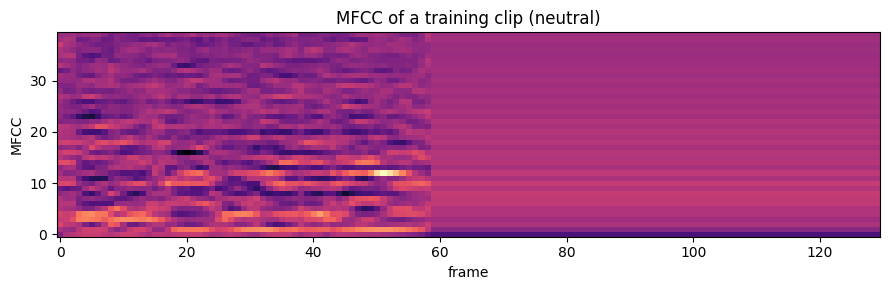

In [6]:
plt.figure(figsize=(9, 3))
plt.imshow(X_tr[0, :, :N_MFCC].T, aspect="auto", origin="lower", cmap="magma")
plt.title(f"MFCC of a training clip ({classes[y_tr[0]]})"); plt.xlabel("frame"); plt.ylabel("MFCC")
plt.tight_layout(); plt.savefig(f"{OUT}/mfcc_example.png", dpi=120); plt.show()

## 7. CNN + BiLSTM model
Conv1D blocks learn local spectral patterns; Bidirectional LSTMs model how emotion evolves over time.

In [7]:
inp = keras.Input(X_tr.shape[1:])
x = inp
for filters, k, drop in [(64, 5, 0.2), (128, 5, 0.3), (256, 3, 0.3)]:
    x = layers.Conv1D(filters, k, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.MaxPooling1D(2)(x)
    x = layers.Dropout(drop)(x)
x = layers.Bidirectional(layers.LSTM(128, return_sequences=True))(x)
x = layers.Bidirectional(layers.LSTM(64))(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.4)(x)
model = keras.Model(inp, layers.Dense(len(classes), activation="softmax")(x), name="cnn_bilstm_ser")
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

I0000 00:00:1795575224.385043      57 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1795575224.391105      57 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "cnn_bilstm_ser"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 130, 122)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 130, 64)        │        39,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 130, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 130, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 65, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 65, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 65, 128)        │        40,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 65, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 65, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 32, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 32, 256)        │        98,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 256)        │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 32, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 16, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 16, 256)        │       394,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 128)            │       164,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 756,232 (2.88 MB)

 Trainable params: 755,336 (2.88 MB)

 Non-trainable params: 896 (3.50 KB)

## 8. Training
Adam, class weights, early stopping and learning-rate reduction.

In [8]:
cw = compute_class_weight("balanced", classes=np.arange(len(classes)), y=y_tr)
hist = model.fit(
    X_tr, y_tr, validation_data=(X_va, y_va), epochs=EPOCHS, batch_size=32, verbose=2,
    class_weight=dict(enumerate(cw)),
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=15, restore_best_weights=True),
               keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-5)])

Epoch 1/100


I0000 00:00:1795575233.335594     175 cuda_dnn.cc:529] Loaded cuDNN version 91002


380/380 - 16s - 41ms/step - accuracy: 0.6631 - loss: 0.9121 - val_accuracy: 0.8630 - val_loss: 0.4003 - learning_rate: 1.0000e-03
Epoch 2/100
380/380 - 5s - 14ms/step - accuracy: 0.8136 - loss: 0.5168 - val_accuracy: 0.8889 - val_loss: 0.3144 - learning_rate: 1.0000e-03
Epoch 3/100
380/380 - 6s - 15ms/step - accuracy: 0.8451 - loss: 0.4350 - val_accuracy: 0.8926 - val_loss: 0.3952 - learning_rate: 1.0000e-03
Epoch 4/100
380/380 - 6s - 14ms/step - accuracy: 0.8694 - loss: 0.3535 - val_accuracy: 0.8963 - val_loss: 0.4115 - learning_rate: 1.0000e-03
Epoch 5/100
380/380 - 6s - 15ms/step - accuracy: 0.8882 - loss: 0.3036 - val_accuracy: 0.8963 - val_loss: 0.3397 - learning_rate: 1.0000e-03
Epoch 6/100
380/380 - 6s - 15ms/step - accuracy: 0.9091 - loss: 0.2552 - val_accuracy: 0.9093 - val_loss: 0.3389 - learning_rate: 1.0000e-03
Epoch 7/100
380/380 - 6s - 15ms/step - accuracy: 0.9217 - loss: 0.2220 - val_accuracy: 0.9074 - val_loss: 0.3453 - learning_rate: 1.0000e-03
Epoch 8/100
380/380 - 6s

## 9. Test-set evaluation

In [9]:
loss, acc = model.evaluate(X_te, y_te, verbose=0)
pred = model.predict(X_te, verbose=0).argmax(1)
print(f"\nTEST accuracy = {acc:.4f}   (chance = {1 / len(classes):.3f})")
print(classification_report(y_te, pred, target_names=classes, digits=4))


TEST accuracy = 0.8500   (chance = 0.125)
              precision    recall  f1-score   support

       angry     0.9091    0.8696    0.8889        92
        calm     0.7073    0.9062    0.7945        32
     disgust     0.8977    0.8587    0.8778        92
        fear     0.8750    0.8370    0.8556        92
       happy     0.7895    0.8152    0.8021        92
     neutral     0.9167    0.8684    0.8919        76
         sad     0.7064    0.8370    0.7662        92
    surprise     0.9873    0.8478    0.9123        92

    accuracy                         0.8500       660
   macro avg     0.8486    0.8550    0.8487       660
weighted avg     0.8598    0.8500    0.8525       660



## 10. Training curves

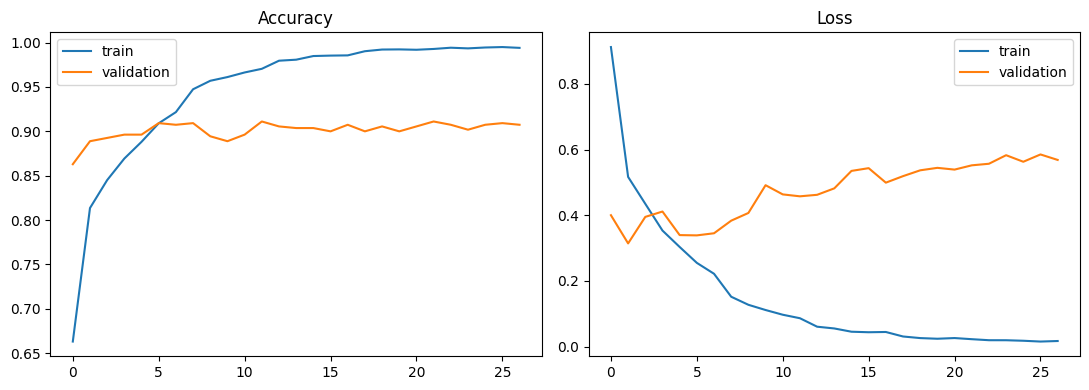

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, k in zip(ax, ["accuracy", "loss"]):
    a.plot(hist.history[k], label="train"); a.plot(hist.history["val_" + k], label="validation")
    a.set_title(k.capitalize()); a.legend()
plt.tight_layout(); plt.savefig(f"{OUT}/training_curves.png", dpi=150); plt.show()

## 11. Confusion matrix — which emotions get mixed up?

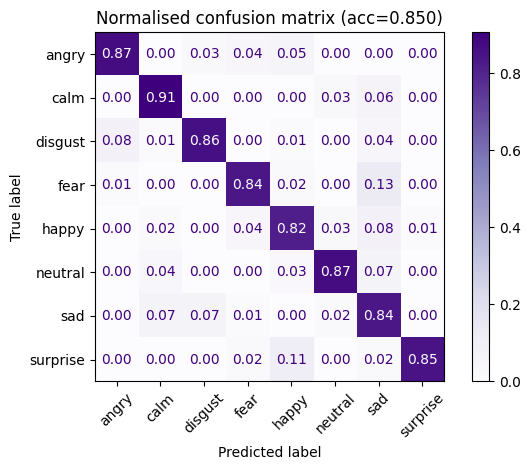

In [11]:
ConfusionMatrixDisplay(confusion_matrix(y_te, pred, normalize="true"), display_labels=classes).plot(
    cmap="Purples", values_format=".2f", xticks_rotation=45)
plt.title(f"Normalised confusion matrix (acc={acc:.3f})")
plt.tight_layout(); plt.savefig(f"{OUT}/confusion_matrix.png", dpi=150); plt.show()

## 12. Save model & predict any audio clip
Upload your own `.wav` as an input and call `predict_emotion(path)`.

In [12]:
model.save(f"{OUT}/emotion_model.keras")
json.dump({"split": SPLIT, "classes": classes, "test_accuracy": round(float(acc), 4)},
          open(f"{OUT}/metrics.json", "w"), indent=2)


def predict_emotion(path):
    x = (extract(load_audio(path)) - mean) / std
    probs = model.predict(x[None], verbose=0)[0]
    return [(classes[i], round(float(probs[i]), 3)) for i in probs.argsort()[::-1][:3]]


print("Demo on a test clip:", te[0]["label"], "->", predict_emotion(te[0]["path"]))
print(f"Saved to {OUT}/   (use predict_emotion('/kaggle/input/.../file.wav') for any clip)")

Demo on a test clip: neutral -> [('sad', 0.566), ('disgust', 0.196), ('happy', 0.119)]
Saved to /kaggle/working/outputs/   (use predict_emotion('/kaggle/input/.../file.wav') for any clip)
